# Notebook 4 · Explain fake videos with click-masked BLIP-2

Use a fresh Kaggle T4 session with Internet enabled. Attach Notebook 1's extracted `metadata.csv` and sibling `crops/` directory, plus Notebook 2's `click_preds.csv`. The two outputs can be in different mounts. Notebook 3 and the original MP4s are unnecessary. Use **Save & Run All** for a full run. For a first trial set `SMOKE=True` below, then start a fresh full session.

Each example contains five chronological crops and one human explanation. A hard circular mask keeps pixels within 20% of the crop width around each predicted click and blacks out the exterior. This is a fake-only explanation task. Validation loss selects the checkpoint. Test generations are exported for Notebook 5. The supplied split contains source overlap, so these results measure performance on the original ExDDV split.

In [1]:
import os, sys, subprocess
os.environ.update(CUDA_VISIBLE_DEVICES="0", HF_HOME="/tmp/hf", TOKENIZERS_PARALLELISM="false", USE_TF="0", USE_FLAX="0")
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "bitsandbytes", "torchao"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers==4.57.6", "peft", "accelerate"], check=True)
# PEFT probes optional quantisation backends even for ordinary linear layers.
# Verify the environment after pip resolves its dependencies.
import importlib
from importlib.util import find_spec
importlib.invalidate_caches()
for backend in ("torchao", "bitsandbytes"):
    if backend in sys.modules or find_spec(backend) is not None:
        raise RuntimeError(f"{backend} is still visible. Start a fresh Kaggle session and run from cell 1.")

In [2]:
import json, hashlib, math, gc, random, shutil, time, platform
from pathlib import Path
import importlib.metadata as packages
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from tqdm.auto import tqdm
from transformers import Blip2ForConditionalGeneration, Blip2Processor

from peft import LoraConfig, TaskType, get_peft_model

META_FILE = None     # Optional absolute metadata.csv path
CLICK_FILE = None    # Optional absolute click_preds.csv path
RESUME_DIR = None    # Optional prior run directory containing latest.pt AND best.pt
SMOKE = False
SEED, RADIUS, FRAMES, SIDE = 42, 0.20, 5, 224
EPOCHS, ACCUM, TEXT_LIMIT = (1 if SMOKE else 10), 4, 96
MODEL_ID = "Salesforce/blip2-flan-t5-xl"
PROMPT = "What is wrong in the images? Explain why they look real or fake."
OUT = Path("/kaggle/working") / ("masked_smoke" if SMOKE else "masked_full")
OUT.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available() and torch.cuda.device_count() == 1, "Start a fresh T4 session with GPU 0 visible."
assert "T4" in torch.cuda.get_device_name(0), torch.cuda.get_device_name(0)
assert 0 < RADIUS <= 1
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
print(torch.cuda.get_device_name(), " | ", OUT)

Tesla T4  |  /kaggle/working/masked_full


## 1. Match each prediction to its video and audit the original split

The key includes the manipulation folder. The five coordinate pairs follow Notebook 1's crop order. Notebook 2 excluded 127 videos from its supervised click experiment and still predicted clicks for them. All videos with captions and valid predictions participate here.

In [3]:
def locate(name, override):
    if override:
        p = Path(override)
        if not p.is_file():
            raise FileNotFoundError(p)
        return p
    hits = sorted(Path("/kaggle/input").rglob(name))
    if name == "metadata.csv":
        hits = [p for p in hits if (p.parent / "crops").is_dir()]
    if len(hits) != 1:
        raise ValueError(f"Set the path override for {name}. Matches: {hits}")
    return hits[0]

def load_inputs(mp, cp):
    meta = pd.read_csv(mp, usecols=["key","movie_name","manipulation","split","text","crop_paths","frame_idx"])
    clicks = pd.read_csv(cp, usecols=["key","split","pred_clicks"])
    df = meta.merge(clicks, on="key", how="outer", validate="one_to_one", indicator=True,
                    suffixes=("", "_click"))
    assert df["_merge"].eq("both").all(), "Mismatch between metadata and predicted video keys."
    assert df.split.eq(df.split_click).all(), "Split disagreement between notebooks."
    assert df.text.fillna("").str.strip().ne("").all(), "Missing explanations."
    for col in ["crop_paths","frame_idx","pred_clicks"]:
        df[col] = df[col].map(json.loads)
    for row in df.itertuples():
        assert row.key == f"{row.manipulation}/{Path(row.movie_name).stem}", row.key
        assert len(row.frame_idx) == FRAMES and row.frame_idx == sorted(row.frame_idx), row.key
        assert row.crop_paths == [f"crops/{row.key}/{i}.png" for i in range(FRAMES)], row.key
        xy = np.asarray(row.pred_clicks, dtype=float)
        assert xy.shape == (FRAMES, 2) and np.isfinite(xy).all() and ((0 <= xy) & (xy <= 1)).all(), row.key
        for rel in row.crop_paths:
            if not (mp.parent / rel).is_file():
                raise FileNotFoundError(mp.parent / rel)
    df["source_id"] = df.key.str.extract(r"/(\d+)_", expand=False)
    assert df.source_id.notna().all()
    return df.drop(columns=["_merge","split_click"])

mp, cp = locate("metadata.csv", META_FILE), locate("click_preds.csv", CLICK_FILE)
df = load_inputs(mp, cp)
counts = df.split.value_counts().to_dict()
assert counts == {"train":2453, "val":269, "test":271}, counts
train_sources = set(df.loc[df.split.eq("train"), "source_id"])
df["source_in_original_train"] = df.source_id.isin(train_sources)
audit = {}
for split in ["val", "test"]:
    part = df[df.split.eq(split)]
    audit[split] = {"videos":len(part), "overlapping_videos":int(part.source_in_original_train.sum()),
                    "shared_source_ids":len(train_sources.intersection(part.source_id))}
print("Original split:", counts, "\nFirst-source overlap:", audit)
if SMOKE:
    df = pd.concat([df[df.split.eq(s)].sample(n=n, random_state=SEED)
                    for s,n in [("train",8),("val",3),("test",3)]])
df = df.sort_values("key").reset_index(drop=True)
ids = {s: df.index[df.split.eq(s)].tolist() for s in counts}

Original split: {'train': 2453, 'test': 271, 'val': 269} 
First-source overlap: {'val': {'videos': 269, 'overlapping_videos': 263, 'shared_source_ids': 248}, 'test': {'videos': 271, 'overlapping_videos': 256, 'shared_source_ids': 236}}


## 2. Inspect what the vision encoder will see

The crosses in the first row show Notebook 2's predictions. Only the second row enters the model. Its regressor achieved 41.4 px test error versus 45.1 px for the reported constant baseline, with little horizontal variation. Check that the retained area contains plausible evidence.

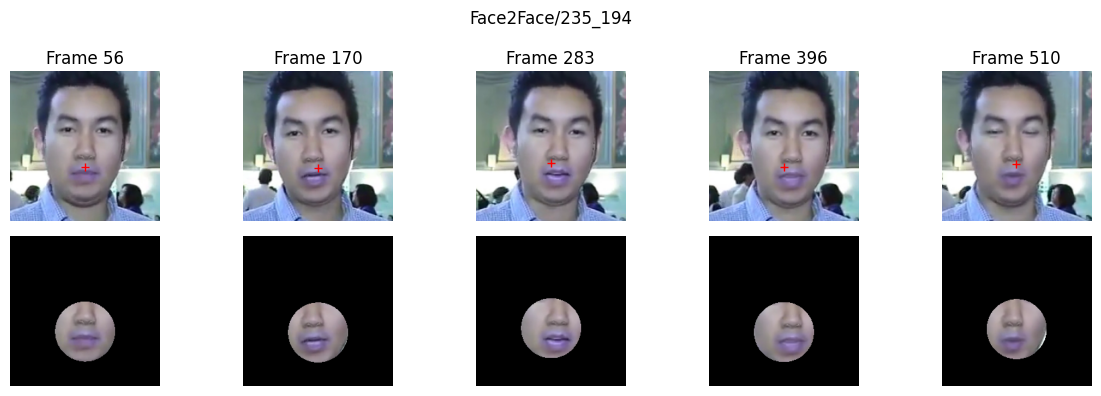

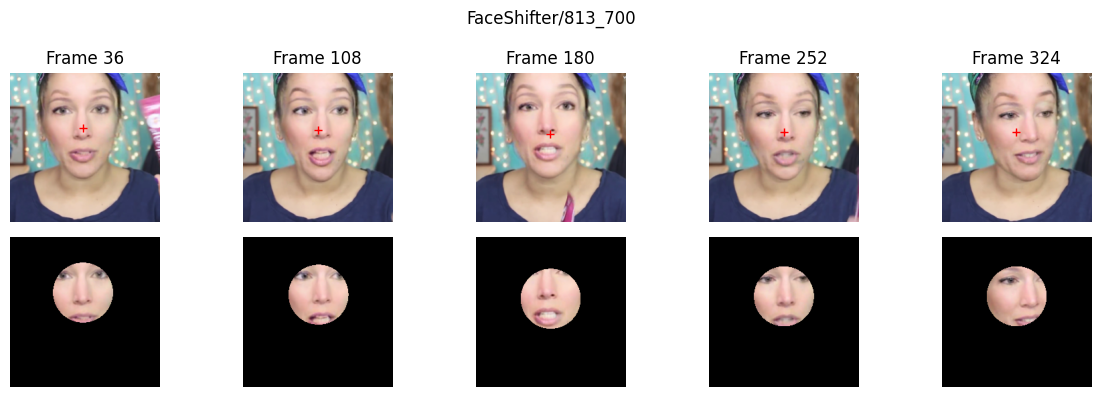

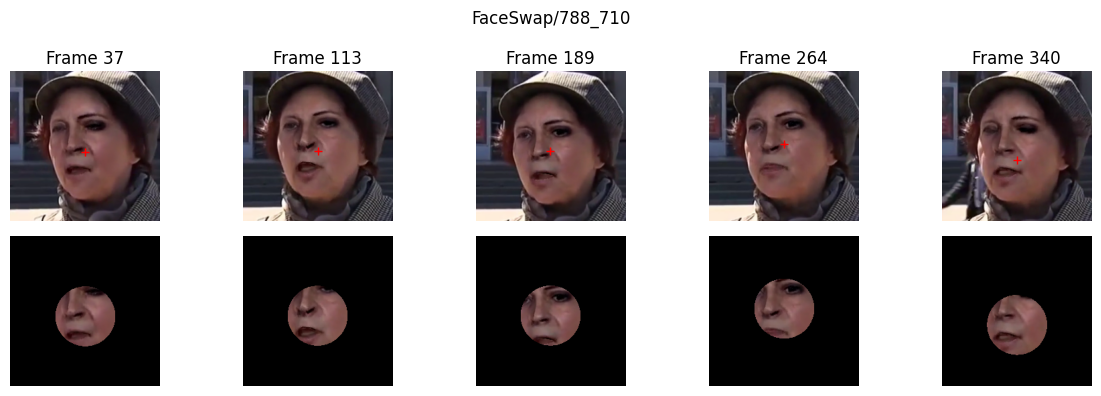

In [4]:
def masked_frame(image, xy):
    w, h = image.size
    if (w,h) != (SIDE,SIDE):
        raise ValueError(f"Expected a 224 px square crop, got {image.size}")
    cx, cy = np.asarray(xy) * [w-1, h-1]
    yy, xx = np.ogrid[:h, :w]
    inside = (xx-cx)**2 + (yy-cy)**2 <= (RADIUS*w)**2
    return Image.fromarray(np.where(inside[..., None], np.asarray(image), 0).astype(np.uint8))

def frame_pair(row, j):
    with Image.open(mp.parent / row.crop_paths[j]) as f:
        image = f.convert("RGB")
    return image, masked_frame(image, row.pred_clicks[j])

for _, row in df[df.split.eq("train")].groupby("manipulation").sample(n=1, random_state=SEED).iterrows():
    fig, axes = plt.subplots(2, FRAMES, figsize=(12,4))
    for j in range(FRAMES):
        original, masked = frame_pair(row,j)
        axes[0,j].imshow(original)
        axes[0,j].plot(*(np.array(row.pred_clicks[j])*(SIDE-1)), "r+")
        axes[0,j].set_title(f"Frame {row.frame_idx[j]}")
        axes[1,j].imshow(masked)
        for ax in axes[:,j]:
            ax.axis("off")
    fig.suptitle(row.key)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 3. Load pretrained BLIP-2 on GPU 0

The adapter is installed and tested on a real training video before the full feature cache is built. Start a fresh T4 session after a failed model load.

In [5]:
gc.collect()
torch.cuda.empty_cache()
free, total = torch.cuda.mem_get_info()
print(f"GPU free {free/2**30:.1f}/{total/2**30:.1f} GiB; /tmp free {shutil.disk_usage('/tmp').free/2**30:.1f} GiB")
device = torch.device("cuda:0")
processor = Blip2Processor.from_pretrained(MODEL_ID)
blip = Blip2ForConditionalGeneration.from_pretrained(
    MODEL_ID, dtype=torch.float16, device_map={"":"cuda:0"}, low_cpu_mem_usage=True)
blip.requires_grad_(False).eval()
model_revision = getattr(blip.config, "_commit_hash", None)
vision = blip.vision_model

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


GPU free 14.5/14.6 GiB; /tmp free 2488.0 GiB


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

## 4. Assemble the video-conditioned language model

The shared Q-Former converts each frame into 32 query vectors. A learned projection and frame-position embedding give the T5 encoder 160 visual tokens followed by the fixed prompt. Train the Q-Former, query tokens, projection, five positions and rank-16 T5 query/value LoRA adapters. Keep the frozen T5 feed-forward output projections and all trainable weights in fp32. Dropout stays off during optimization, as in the smoke test.

In [6]:
class VideoBlip2(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.qformer = base.qformer.float().requires_grad_(True)
        self.queries = base.query_tokens.float().detach().clone()
        self.queries = nn.Parameter(self.queries)
        self.project = base.language_projection.float().requires_grad_(True)
        self.positions = nn.Parameter(torch.zeros(FRAMES, self.project.out_features, device=device))
        nn.init.normal_(self.positions, std=0.01)
        for name, mod in base.language_model.named_modules():
            if name.endswith(".wo"):
                mod.float()
        self.lm = get_peft_model(base.language_model, LoraConfig(
            task_type=TaskType.SEQ_2_SEQ_LM, r=16, lora_alpha=32, lora_dropout=0.,
            target_modules=["q","v"], bias="none"))
        for p in self.lm.parameters():
            if p.requires_grad:
                p.data = p.data.float()
        self.lm.config.use_cache = False
        self.register_buffer("prompt_ids", processor.tokenizer(PROMPT, return_tensors="pt").input_ids.to(device))

    def inputs(self, feats):
        b, t, patches, dim = feats.shape
        vision_tokens = feats.reshape(b*t, patches, dim).float()
        q = self.qformer(query_embeds=self.queries.expand(b*t,-1,-1),
                         encoder_hidden_states=vision_tokens, return_dict=True).last_hidden_state
        projected = self.project(q).reshape(b,t,q.shape[1],-1)
        visual = (projected + self.positions[None,:,None,:]).flatten(1,2)
        prompt = self.lm.get_input_embeddings()(self.prompt_ids.expand(b,-1))
        inputs = torch.cat([visual.to(prompt.dtype), prompt], dim=1)
        return {"inputs_embeds":inputs, "attention_mask":torch.ones(inputs.shape[:2], device=device, dtype=torch.long)}

    def forward(self, feats, labels):
        decoder_ids = self.lm.get_base_model()._shift_right(labels)
        logits = self.lm(**self.inputs(feats), decoder_input_ids=decoder_ids, use_cache=False).logits
        return nn.functional.cross_entropy(logits.float().reshape(-1, logits.shape[-1]),
                                           labels.reshape(-1), ignore_index=-100)

model = VideoBlip2(blip).eval()
del blip
params = dict((n,p) for n,p in model.named_parameters() if p.requires_grad)
assert all(p.dtype == torch.float32 for p in params.values())
assert model.queries.shape[1] == 32
print(f"{sum(p.numel() for p in params.values()):,} trainable parameters")

116,184,576 trainable parameters


### One-video preflight

This uses one real masked training video to check the loss, LoRA gradients and beam decoding. It makes no optimiser update.

In [7]:
def encode_video(row):
    frames = [frame_pair(row, j)[1] for j in range(FRAMES)]
    pixels = processor.image_processor(images=frames, return_tensors="pt").pixel_values
    with torch.no_grad():
        tokens = vision(pixel_values=pixels.to(device, torch.float16)).last_hidden_state
    if not torch.isfinite(tokens).all():
        raise FloatingPointError(f"Nonfinite ViT output: {row.key}")
    return tokens

def check_training_path():
    row = df.iloc[ids["train"][0]]
    feats = encode_video(row).unsqueeze(0)
    # Training normally runs after releasing the vision encoder.
    vision.cpu()
    torch.cuda.empty_cache()
    labels = processor.tokenizer(row.text, max_length=TEXT_LIMIT, truncation=True,
                                 return_tensors="pt").input_ids.to(device)
    try:
        loss = model(feats, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("Nonfinite loss in the one-video preflight.")
        loss.backward()
        adapter_grads = [p.grad for n,p in params.items() if "lora_B" in n and p.grad is not None]
        if not adapter_grads or not all(torch.isfinite(g).all() for g in adapter_grads):
            raise FloatingPointError("Missing or nonfinite LoRA gradients in preflight.")
        with torch.no_grad():
            sample = model.lm.generate(**model.inputs(feats), num_beams=3, max_new_tokens=3,
                                       do_sample=False, use_cache=True)
        assert sample.ndim == 2 and sample.shape[0] == 1
        print(f"Preflight passed on {row.key}: loss {loss.item():.3f}, backward and beam generation OK.")
    finally:
        model.zero_grad(set_to_none=True)

check_training_path()
gc.collect()
torch.cuda.empty_cache()
vision.to(device)

Preflight passed on Face2Face/000_003: loss 3.064, backward and beam generation OK.


Blip2VisionModel(
  (embeddings): Blip2VisionEmbeddings(
    (patch_embedding): Conv2d(3, 1408, kernel_size=(14, 14), stride=(14, 14))
  )
  (encoder): Blip2Encoder(
    (layers): ModuleList(
      (0-38): 39 x Blip2EncoderLayer(
        (self_attn): Blip2Attention(
          (qkv): Linear(in_features=1408, out_features=4224, bias=True)
          (projection): Linear(in_features=1408, out_features=1408, bias=True)
        )
        (layer_norm1): LayerNorm((1408,), eps=1e-06, elementwise_affine=True)
        (mlp): Blip2MLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=1408, out_features=6144, bias=True)
          (fc2): Linear(in_features=6144, out_features=1408, bias=True)
        )
        (layer_norm2): LayerNorm((1408,), eps=1e-06, elementwise_affine=True)
      )
    )
  )
  (post_layernorm): LayerNorm((1408,), eps=1e-06, elementwise_affine=True)
)

### Cache masked ViT features

The full run writes about 11 GB of temporary fp16 features. Only the frozen vision encoder is cached. Both training and generation use the trainable Q-Former.

In [8]:
patch = vision.config.patch_size
shape = (len(df), FRAMES, (SIDE//patch)**2 + 1, vision.config.hidden_size)
cache_path = Path("/tmp") / (OUT.name + "_vit.npy")
# A new cache is always built, including after a resumed Kaggle session.
if cache_path.exists():
    cache_path.unlink()
needed = math.prod(shape)*2
if shutil.disk_usage("/tmp").free < needed + 512*2**20:
    raise OSError(f"Need {needed/2**30:.2f} GiB plus headroom free in /tmp after download.")
features = np.lib.format.open_memmap(cache_path, mode="w+", dtype=np.float16, shape=shape)
with torch.inference_mode():
    for i, row in enumerate(tqdm(df.itertuples(), total=len(df), desc="Masked ViT features")):
        features[i] = encode_video(row).cpu().numpy()
features.flush()
del vision
gc.collect()
torch.cuda.empty_cache()

Masked ViT features:   0%|          | 0/2993 [00:00<?, ?it/s]

## 5. Fit using training captions and choose the epoch by validation loss

Use one video per microbatch and four per optimizer update. The Q-Former starts at a lower learning rate than the new projection adaptation and LoRA weights. Match these settings, seed, decoding and preprocessing to Notebook 3 for a controlled comparison. The last partial accumulation group takes an update. Each completed epoch atomically replaces the latest resumable checkpoint. A separate file keeps the best weights.

In [9]:
def batch(i):
    feats = torch.from_numpy(features[i:i+1]).to(device)
    labels = processor.tokenizer([df.at[i,"text"]], padding=True, truncation=True,
                                 max_length=TEXT_LIMIT, return_tensors="pt")
    target = labels.input_ids.masked_fill(labels.attention_mask.eq(0), -100)
    return feats, target.to(device)

@torch.no_grad()
def validation_loss(indices):
    total, tokens = 0., 0
    for i in indices:
        x,y = batch(i)
        n = int(y.ne(-100).sum())
        total += float(model(x,y)) * n
        tokens += n
    result = total / tokens
    if not math.isfinite(result):
        raise FloatingPointError("Nonfinite evaluation loss.")
    return result

settings = dict(model=MODEL_ID, revision=model_revision, prompt=PROMPT, radius=RADIUS,
                side=SIDE, frames=FRAMES, seed=SEED, accum=ACCUM, max_length=TEXT_LIMIT,
                qformer_lr=1e-5, other_lr=2e-4, rank=16, alpha=32, mask_fill="black",
                metadata_sha256=hashlib.sha256(mp.read_bytes()).hexdigest(),
                clicks_sha256=hashlib.sha256(cp.read_bytes()).hexdigest(),
                selected_keys=hashlib.sha256("\n".join(df.key).encode()).hexdigest(),
                versions={p:packages.version(p) for p in ["torch","transformers","peft","accelerate"]})
(OUT/"run.json").write_text(json.dumps(dict(settings=settings, source_overlap=audit, counts=counts,
                                         smoke=SMOKE, epochs=EPOCHS), indent=2))
optimizer = torch.optim.AdamW([
    {"params": list(model.qformer.parameters()), "lr":settings["qformer_lr"]},
    {"params": [p for n,p in params.items() if not n.startswith("qformer.")], "lr":settings["other_lr"]}],
    weight_decay=0.01, foreach=False)
scaler = torch.amp.GradScaler("cuda", init_scale=1024)
def weights():
    return {n:p.detach().cpu() for n,p in params.items()}

def restore(state):
    assert state.keys() == params.keys(), "Trainable parameter set differs."
    with torch.no_grad():
        for n,p in params.items():
            p.copy_(state[n])

def save_atomic(obj, path):
    tmp = path.with_suffix(".tmp")
    torch.save(obj,tmp)
    tmp.replace(path)

history, best, start = [], float("inf"), 1
resume = Path(RESUME_DIR) if RESUME_DIR else OUT
if RESUME_DIR or (OUT/"latest.pt").is_file():
    ck = torch.load(resume/"latest.pt", map_location="cpu", weights_only=True)
    assert ck["settings"] == settings, "Data, packages or configuration changed. Use a fresh output folder."
    restore(ck["weights"])
    optimizer.load_state_dict(ck["optimizer"])
    scaler.load_state_dict(ck["scaler"])
    start, history, best = ck["epoch"]+1, ck["history"], ck["best"]
    # Best is stored first. A killed write may leave best.pt one epoch ahead;
    # replay that epoch from latest.pt before using the best checkpoint.
    if resume.resolve() != OUT.resolve():
        shutil.copyfile(resume/"best.pt", OUT/"best.pt")
    assert (OUT/"best.pt").is_file()
    del ck
for epoch in range(start, EPOCHS+1):
    model.eval()
    order = np.random.default_rng(SEED+epoch).permutation(ids["train"]).tolist()
    running, ntokens, updates = 0., 0, 0
    t0 = time.monotonic()
    for begin in tqdm(range(0,len(order),ACCUM), desc=f"Epoch {epoch}"):
        group = order[begin:begin+ACCUM]
        optimizer.zero_grad(set_to_none=True)
        for i in group:
            x,y = batch(i)
            loss = model(x,y)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Nonfinite training loss: {df.at[i,'key']}")
            scaler.scale(loss/len(group)).backward()
            n = int(y.ne(-100).sum())
            running += float(loss.detach()) * n
            ntokens += n
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(list(params.values()),1.0)
        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        updates += int(scaler.get_scale() >= old_scale)
    if updates == 0:
        raise FloatingPointError("GradScaler skipped every update.")
    optimizer.zero_grad(set_to_none=True)
    val = validation_loss(ids["val"])
    record = dict(epoch=epoch, train_loss=running/ntokens, val_loss=val, updates=updates,
                  seconds=round(time.monotonic()-t0,1))
    history.append(record)
    state = weights()
    if val < best:
        best = val
        save_atomic(dict(weights=state, epoch=epoch, val_loss=val, settings=settings), OUT/"best.pt")
    save_atomic(dict(weights=state, epoch=epoch, best=best, optimizer=optimizer.state_dict(),
                     scaler=scaler.state_dict(), history=history, settings=settings), OUT/"latest.pt")
    del state
    pd.DataFrame(history).to_csv(OUT/"history.csv", index=False)
    print(record, flush=True)

Epoch 1:   0%|          | 0/614 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.8532904140431377, 'val_loss': 1.7245080546705824, 'updates': 614, 'seconds': 953.3}


Epoch 2:   0%|          | 0/614 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.551407269074244, 'val_loss': 1.6270515006946973, 'updates': 614, 'seconds': 937.6}


Epoch 3:   0%|          | 0/614 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.407579433385702, 'val_loss': 1.5833109510997017, 'updates': 614, 'seconds': 934.7}


... (10 outputs left out)

Epoch 9:   0%|          | 0/614 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.6486512364545799, 'val_loss': 2.204838888258574, 'updates': 614, 'seconds': 934.3}


Epoch 10:   0%|          | 0/614 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 0.5555475429209005, 'val_loss': 2.560069300172207, 'updates': 614, 'seconds': 934.7}


## 6. Generate held-out explanations from the best epoch

Decode once per original test video, with the same fixed prompt and five masked frames. The CSV preserves keys, references and manipulation labels for Notebook 5. The constant sentence is included for downstream scoring. A shared source ID can affect comparability to unseen identities. Training-video clicks were predicted in-sample, and extremely similar texts across different videos can reflect learned phrasing rather than visual grounding.

In [10]:
ck = torch.load(OUT/"best.pt", map_location="cpu", weights_only=True)
assert ck["settings"] == settings
restore(ck["weights"])
best_epoch = ck["epoch"]
del ck
model.eval()
test_loss = validation_loss(ids["test"])
rows = []
with torch.inference_mode():
    for i in tqdm(ids["test"], desc="Generate test captions"):
        x = torch.from_numpy(features[i:i+1]).to(device)
        seq = model.lm.generate(**model.inputs(x), max_new_tokens=64, num_beams=3,
                                do_sample=False, use_cache=True)
        r = df.iloc[i]
        rows.append(dict(key=r.key, movie_name=r.movie_name, manipulation=r.manipulation, split=r.split,
                         source_id=r.source_id, source_in_original_train=bool(r.source_in_original_train),
                         reference=r.text, prediction=processor.tokenizer.decode(seq[0], skip_special_tokens=True).strip(),
                         constant_prediction="The eyes are blurry."))
results = pd.DataFrame(rows)
assert results.key.is_unique and len(results) == len(ids["test"])
results.to_csv(OUT/"test_predictions.csv", index=False)
summary = dict(best_epoch=best_epoch, test_token_loss=test_loss, test_videos=len(results),
               unique_predictions=results.prediction.nunique(), empty_predictions=int(results.prediction.eq("").sum()),
               peak_gpu_GiB=round(torch.cuda.max_memory_allocated()/2**30,2))
(OUT/"test_summary.json").write_text(json.dumps(summary,indent=2))
print(summary)
print(results.prediction.value_counts().head(5))
display(results.groupby("manipulation").head(2)[["key","reference","prediction"]])

Generate test captions:   0%|          | 0/271 [00:00<?, ?it/s]

{'best_epoch': 3, 'test_token_loss': 1.6202285307201933, 'test_videos': 271, 'unique_predictions': 37, 'empty_predictions': 0, 'peak_gpu_GiB': 10.88}
prediction
Artifacts on the mouth and on the left side of the face.           45
The light is flickering on the face.                               44
The eyebrows are doubled.                                          43
The mouth is smearing.                                             39
The eyebrows are doubled. There are artifacts around the mouth.    16
Name: count, dtype: int64


,key,reference,prediction
0,Face2Face/024_073,The shadow in the chin is not visible at all t...,Artifacts on the mouth.
1,Face2Face/025_067,Artifacts on the chin and on the nose.,The mouth is smearing.
90,FaceShifter/021_312,The eyebrows are doubled.,Artifacts on the mouth and on the left side of...
91,FaceShifter/030_193,There are glitches on the face.,The eyebrows are doubled. The mouth is smearing.
180,FaceSwap/001_870,Artifacts all over the face. Face looks unnatu...,Artifacts on the mouth.
181,FaceSwap/010_005,Face looks unnatural. Strange contrasts.,The eyebrows are doubled.
